Dataset loaded successfully!

Original dataset shape: (541909, 8)

Cleaned sales records: 524878
Unique invoices: 19960
Unique customers: 4338
Total revenue: £10,642,110.80

MONTHLY SALES AND REVENUE GROWTH
                 Revenue  GrowthPercent
InvoiceMonth                           
2010-12        821452.73            NaN
2011-01        689811.61         -16.03
2011-02        522545.56         -24.25
2011-03        716215.26          37.06
2011-04        536968.49         -25.03
2011-05        769296.61          43.27
2011-06        760547.01          -1.14
2011-07        718076.12          -5.58
2011-08        757841.38           5.54
2011-09       1056435.19          39.40
2011-10       1151263.73           8.98
2011-11       1503866.78          30.63
2011-12        637790.33         -57.59

TOP 10 PRODUCTS BY REVENUE
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HAN

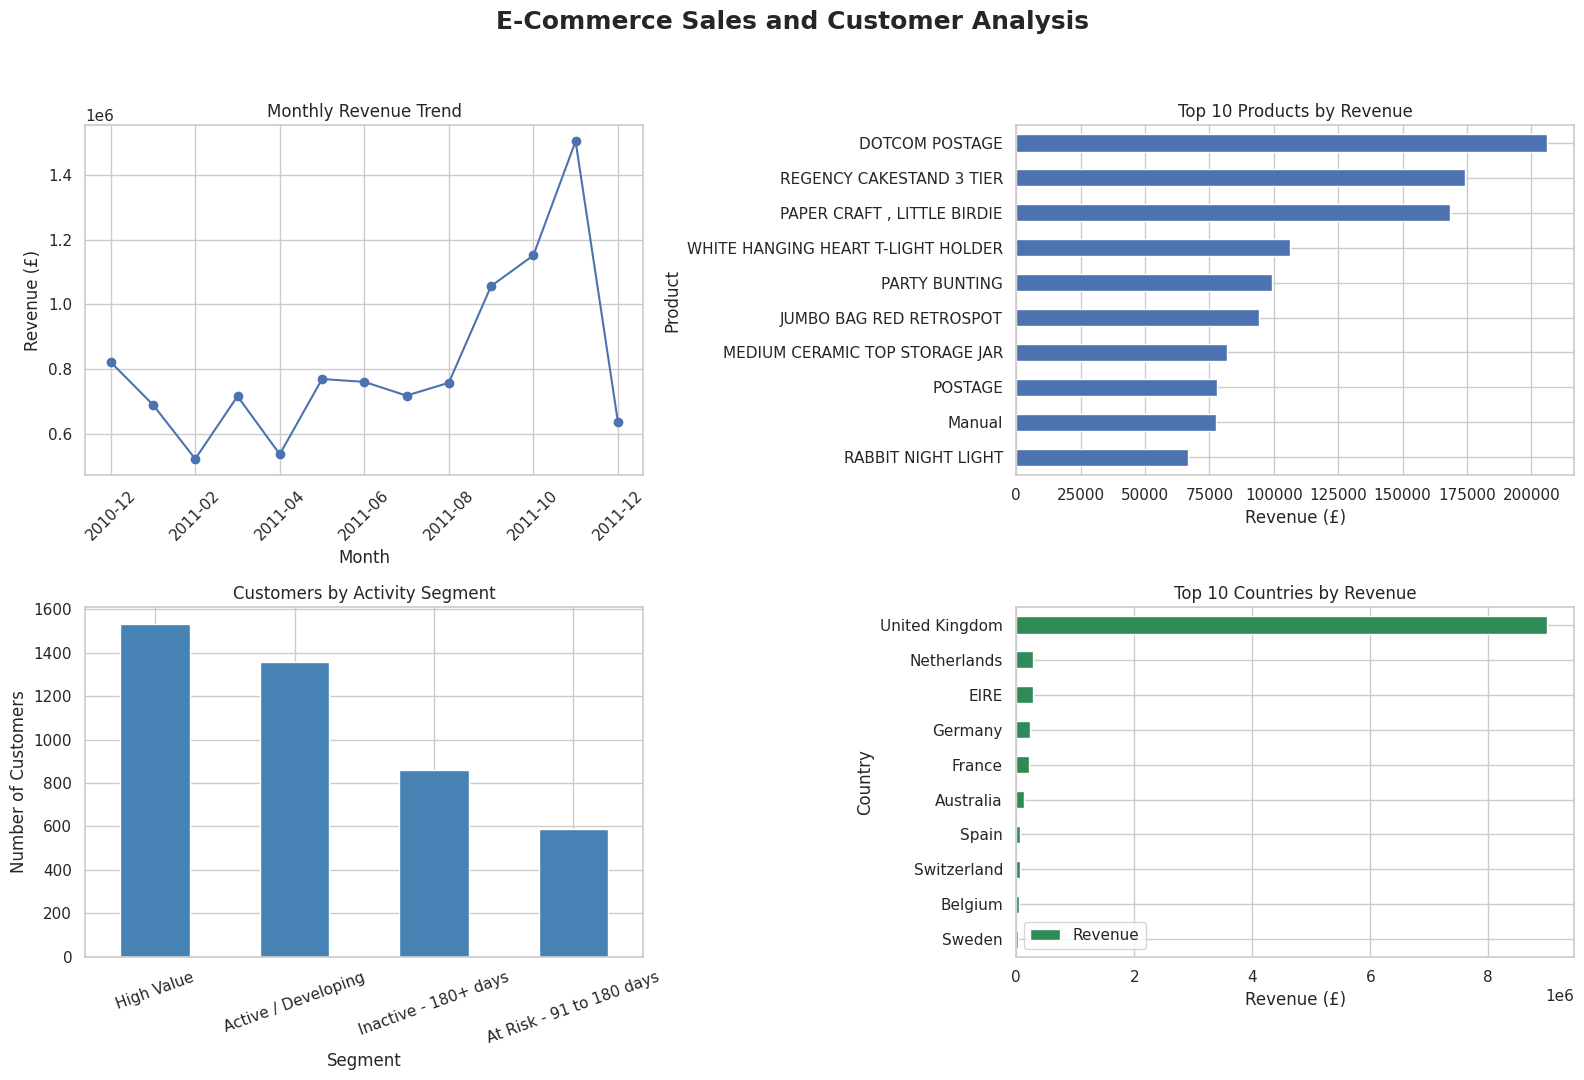


BUSINESS INSIGHTS AND RECOMMENDATIONS
1. Highest-revenue month: 2011-11
2. Highest-revenue product: DOTCOM POSTAGE
3. Leading country by revenue: United Kingdom
4. Customers inactive for over 180 days: 860
5. Customers at risk due to inactivity: 589

RECOMMENDATIONS:
- Offer suitable promotions to inactive customers.
- Use loyalty rewards to encourage repeat purchases.
- Maintain stock of high-revenue products.
- Plan marketing campaigns around strong sales periods.
- Investigate sales performance in lower-revenue markets.

Analysis completed successfully!
Saved: customer_churn_sales_analysis.png
Saved: monthly_sales_analysis.csv
Saved: customer_segments.csv


In [1]:
# ============================================================
# TASK 3: CUSTOMER CHURN / SALES TREND ANALYSIS
# Tools: Python, Pandas, Matplotlib, Seaborn
# Dataset: UCI Online Retail
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile
import io
import os

# 1. DOWNLOAD AND LOAD REAL E-COMMERCE DATASET
print("Downloading dataset...")

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

try:
    response = urllib.request.urlopen(url, timeout=60)
    with zipfile.ZipFile(io.BytesIO(response.read())) as z:
        excel_file = next(
            f for f in z.namelist()
            if f.lower().endswith((".xlsx", ".xls"))
        )
        with z.open(excel_file) as file:
            df = pd.read_excel(file)

    print("Dataset loaded successfully!")

except Exception as e:
    print("Dataset download failed.")
    print("Please check your internet connection and run again.")
    raise e

# 2. DATA CLEANING
print("\nOriginal dataset shape:", df.shape)

df.columns = df.columns.str.strip()
df = df.drop_duplicates()

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df = df.dropna(subset=[
    "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"
])

# Separate cancelled invoices and returns
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

returns = df[cancelled | (df["Quantity"] < 0)].copy()

# Keep valid sales transactions
sales = df[
    ~cancelled &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

# 3. FEATURE ENGINEERING AND DATE EXTRACTION
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Month"] = sales["InvoiceDate"].dt.month
sales["MonthName"] = sales["InvoiceDate"].dt.strftime("%b")
sales["Day"] = sales["InvoiceDate"].dt.day_name()

sales["InvoiceMonth"] = (
    sales["InvoiceDate"].dt.to_period("M").astype(str)
)

print("\nCleaned sales records:", len(sales))
print("Unique invoices:", sales["InvoiceNo"].nunique())
print("Unique customers:", sales["CustomerID"].nunique())
print("Total revenue: £{:,.2f}".format(sales["Revenue"].sum()))

# 4. MONTHLY SALES TREND AND PIVOT TABLE
monthly_sales = sales.pivot_table(
    index="InvoiceMonth",
    values="Revenue",
    aggfunc="sum"
).sort_index()

monthly_sales["GrowthPercent"] = (
    monthly_sales["Revenue"].pct_change() * 100
)

print("\nMONTHLY SALES AND REVENUE GROWTH")
print(monthly_sales.round(2).to_string())

# 5. TOP PRODUCTS
top_products = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 PRODUCTS BY REVENUE")
print(top_products.round(2).to_string())

# 6. CUSTOMER SEGMENTATION
customer_data = sales.dropna(subset=["CustomerID"]).copy()

customer_summary = customer_data.groupby("CustomerID").agg(
    TotalOrders=("InvoiceNo", "nunique"),
    TotalRevenue=("Revenue", "sum"),
    LastPurchase=("InvoiceDate", "max")
)

reference_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_summary["DaysInactive"] = (
    reference_date - customer_summary["LastPurchase"]
).dt.days

# Simple, transparent activity-based segments
def segment_customer(row):
    if row["DaysInactive"] > 180:
        return "Inactive - 180+ days"
    elif row["DaysInactive"] > 90:
        return "At Risk - 91 to 180 days"
    elif row["TotalOrders"] >= 3 and row["TotalRevenue"] >= customer_summary["TotalRevenue"].median():
        return "High Value"
    else:
        return "Active / Developing"

customer_summary["Segment"] = customer_summary.apply(
    segment_customer, axis=1
)

segment_summary = customer_summary.groupby("Segment").agg(
    Customers=("TotalRevenue", "size"),
    Revenue=("TotalRevenue", "sum")
).sort_values("Revenue", ascending=False)

print("\nCUSTOMER SEGMENT ANALYSIS")
print(segment_summary.round(2).to_string())

# 7. COUNTRY-WISE REVENUE PIVOT TABLE
country_sales = sales.pivot_table(
    index="Country",
    values="Revenue",
    aggfunc="sum"
).sort_values("Revenue", ascending=False)

print("\nTOP 10 COUNTRIES BY REVENUE")
print(country_sales.head(10).round(2).to_string())

# 8. VISUALIZATION DASHBOARD
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    "E-Commerce Sales and Customer Analysis",
    fontsize=18, fontweight="bold"
)

# Chart 1: Monthly revenue
monthly_sales["Revenue"].plot(
    kind="line", marker="o", ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue (£)")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: Top products
top_products.sort_values().plot(
    kind="barh", ax=axes[0, 1]
)
axes[0, 1].set_title("Top 10 Products by Revenue")
axes[0, 1].set_xlabel("Revenue (£)")
axes[0, 1].set_ylabel("Product")

# Chart 3: Customer segments
segment_summary["Customers"].plot(
    kind="bar", ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set_title("Customers by Activity Segment")
axes[1, 0].set_xlabel("Segment")
axes[1, 0].set_ylabel("Number of Customers")
axes[1, 0].tick_params(axis="x", rotation=20)

# Chart 4: Country revenue
country_sales.head(10).sort_values("Revenue").plot(
    kind="barh", ax=axes[1, 1], color="seagreen"
)
axes[1, 1].set_title("Top 10 Countries by Revenue")
axes[1, 1].set_xlabel("Revenue (£)")
axes[1, 1].set_ylabel("Country")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    "customer_churn_sales_analysis.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# 9. ACTIONABLE BUSINESS RECOMMENDATIONS
print("\n" + "=" * 55)
print("BUSINESS INSIGHTS AND RECOMMENDATIONS")
print("=" * 55)

best_month = monthly_sales["Revenue"].idxmax()
best_product = top_products.index[0]
best_country = country_sales.index[0]

print(f"1. Highest-revenue month: {best_month}")
print(f"2. Highest-revenue product: {best_product}")
print(f"3. Leading country by revenue: {best_country}")

inactive_count = (
    customer_summary["Segment"] == "Inactive - 180+ days"
).sum()

at_risk_count = (
    customer_summary["Segment"] == "At Risk - 91 to 180 days"
).sum()

print(f"4. Customers inactive for over 180 days: {inactive_count}")
print(f"5. Customers at risk due to inactivity: {at_risk_count}")

print("\nRECOMMENDATIONS:")
print("- Offer suitable promotions to inactive customers.")
print("- Use loyalty rewards to encourage repeat purchases.")
print("- Maintain stock of high-revenue products.")
print("- Plan marketing campaigns around strong sales periods.")
print("- Investigate sales performance in lower-revenue markets.")

# 10. EXPORT RESULTS
monthly_sales.to_csv("monthly_sales_analysis.csv")
customer_summary.to_csv("customer_segments.csv")

print("\nAnalysis completed successfully!")
print("Saved: customer_churn_sales_analysis.png")
print("Saved: monthly_sales_analysis.csv")
print("Saved: customer_segments.csv")